# Example of the aitlas toolbox in the context of object detection

This notebook showcases an object detection example with the track 1 data of DFC23.

## Import the required packages

In [ ]:
from aitlas.datasets import DFC23Dataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Show images and bounding boxes

Total number of patches: 3551


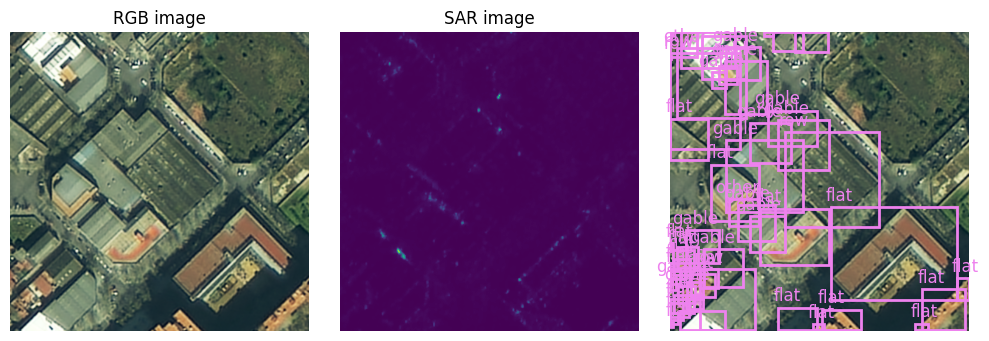

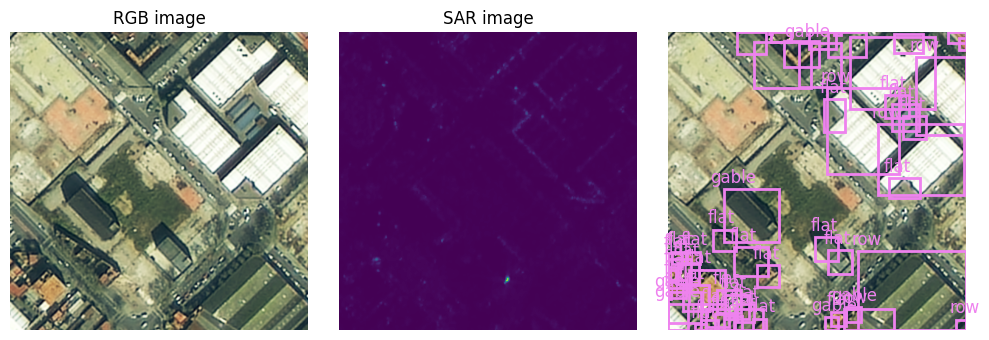

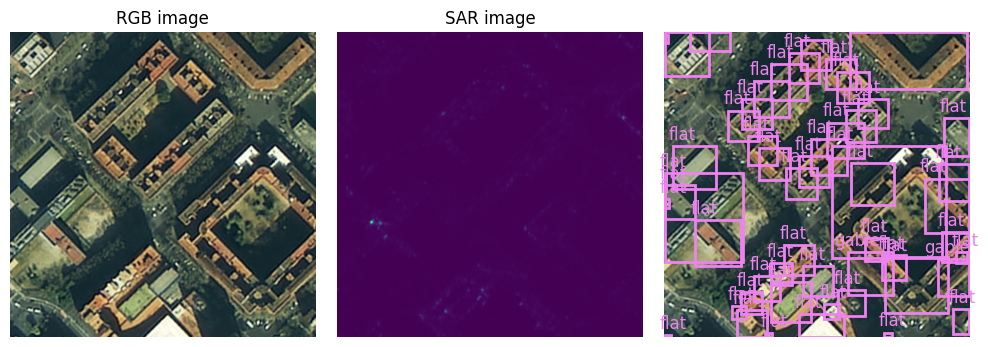

In [ ]:
dataset_config = {
    "data_dir": "./data/dfc23/track1/train",
    "annotation_dir": "./data/dfc23/track1/roof_fine_train_corrected.json",
    "selection": "rgb & sar"
}
dataset = DFC23Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(20);
dataset.show_image(50);
dataset.show_image(65);

Sentinel-2 images

In [ ]:
dataset_config = {
    "data_dir": "./data/dfc23/track1/train",
    "annotation_dir": "./data/dfc23/track1/roof_fine_train_corrected.json",
    "selection": "rgb"
}
dataset = DFC23Dataset(dataset_config)

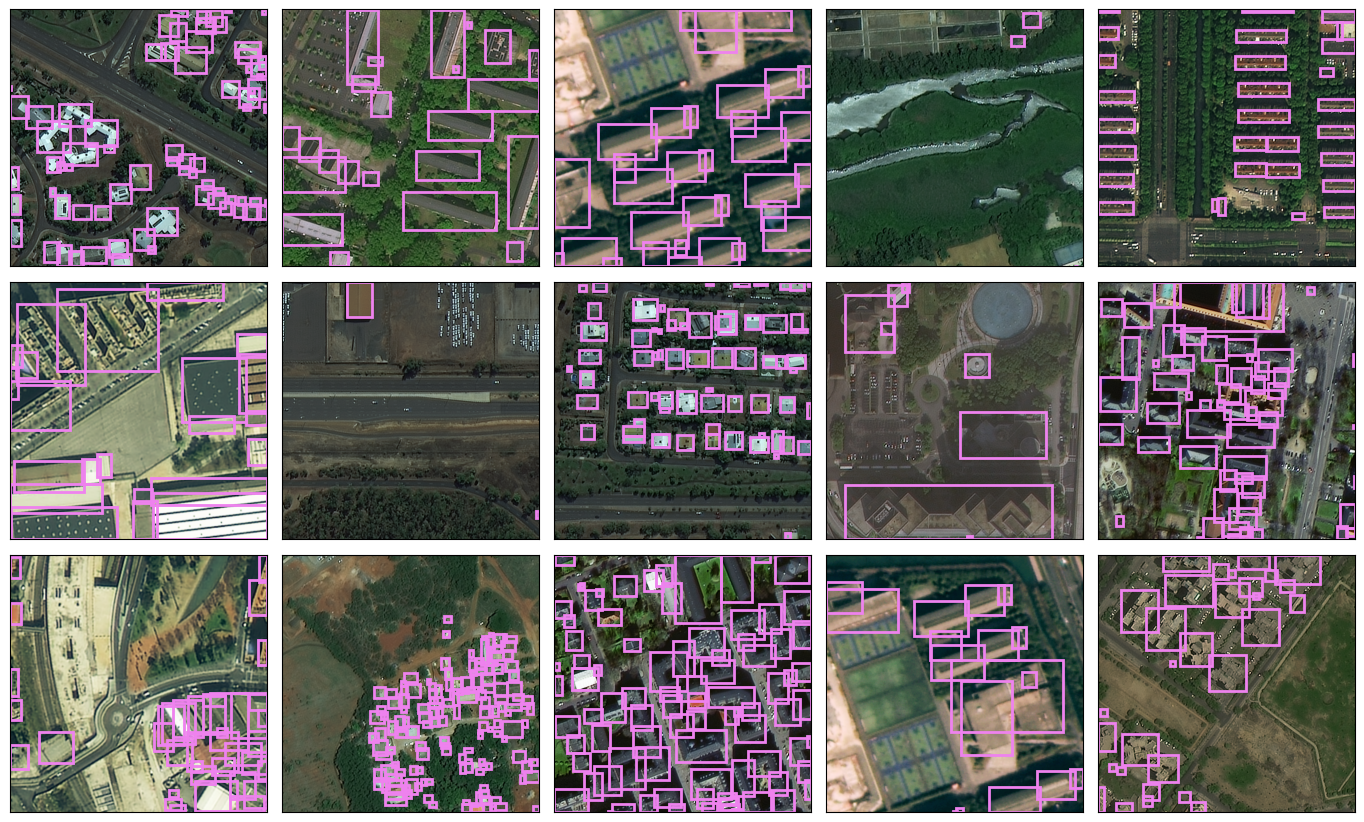

In [97]:
dataset.show_batch(15);

In [72]:
dataset.data_distribution_table()

,Label,Count
0,flat,109640
1,gable,57426
2,gambrel,5087
3,row,943
4,multiple eave,738
5,hipped v1,4320
6,hipped v2,10220
7,mansard,510
8,pyramid,1520
9,arched,833


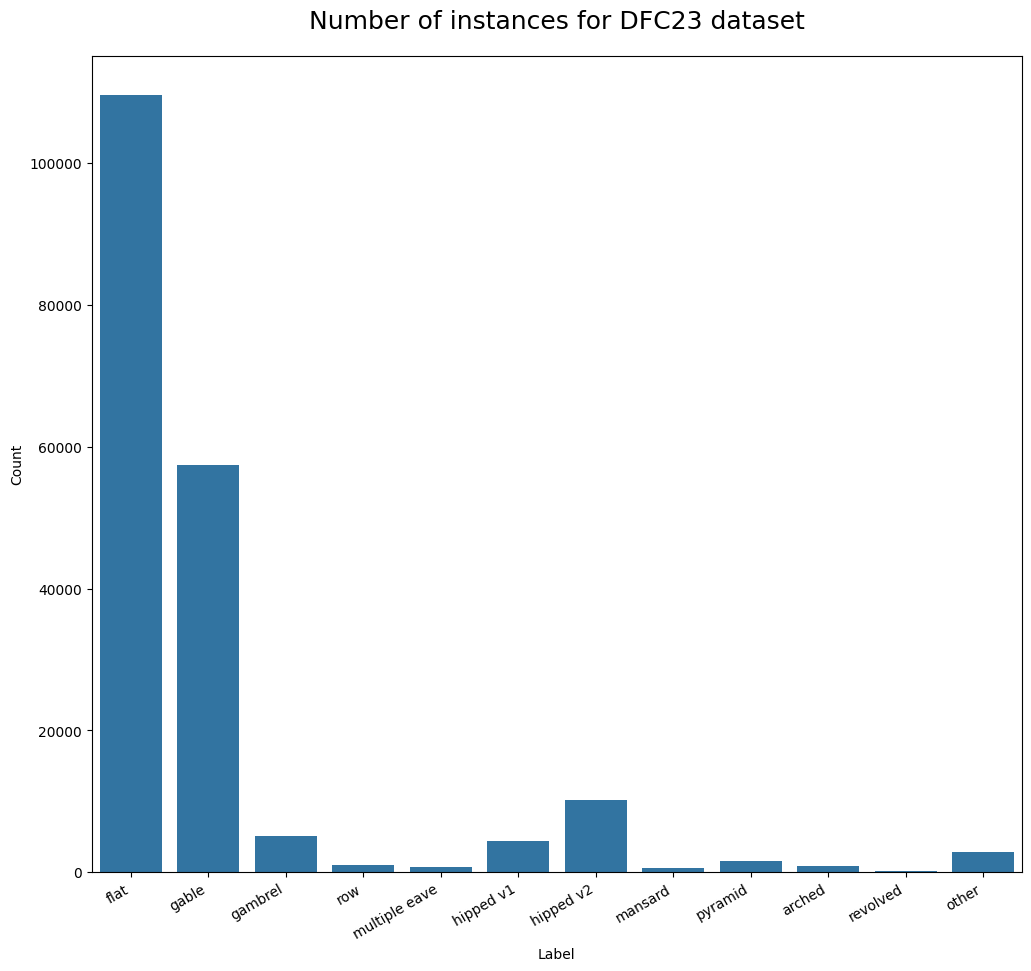

In [73]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/dfc23/track1/train",
    "annotation_dir": "./data/dfc23/track1/roof_fine_train_corrected.json",
    "selection": "rgb",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = DFC23Dataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 3551


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/dfc23"
model_config = {
    "num_classes": 13,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [8]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-12-29 13:22:18,396 INFO Starting training.
training: 100%|██████████| 444/444 [36:55<00:00,  4.99s/it]
2025-12-29 13:59:14,599 INFO epoch: 1, time: 2216, loss:  1.31025
testing on train set: 100%|██████████| 444/444 [36:54<00:00,  4.99s/it]
2025-12-29 14:39:26,516 INFO map:0.06462164223194122, map_50:0.1083064004778862, map_75:0.0706474632024765, map_small:0.038703132420778275, map_medium:0.09081795811653137, map_large:0.10059212893247604, mar_1:0.012824744917452335, mar_10:0.05746021866798401, mar_100:0.09450340270996094, mar_small:0.059861183166503906, mar_medium:0.13003940880298615, mar_large:0.13466715812683105, map_per_class:tensor(0.1960), tensor(0.2219), tensor(0.1647), tensor(0.0050), tensor(0.), tensor(0.), tensor(0.1280), tensor(0.), tensor(0.0510), tensor(0.), tensor(0.), tensor(0.0089), mar_100_per_class:tensor(0.2715), tensor(0.3455), tensor(0.2656), tensor(0.0005), tensor(0.), tensor(0.), tensor(0.1897), tensor(0.), tensor(0.0609), tensor(0.), tensor(0.), tensor(0.00

## Predictions

2025-12-30 09:14:07,903 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/dfc23/checkpoint.pth.tar
2025-12-30 09:14:08,163 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/dfc23/checkpoint.pth.tar at epoch 11


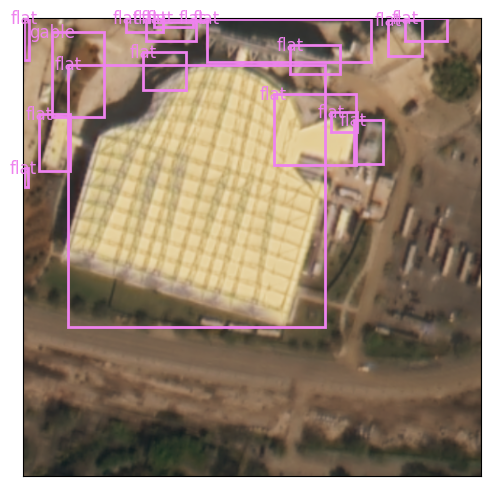

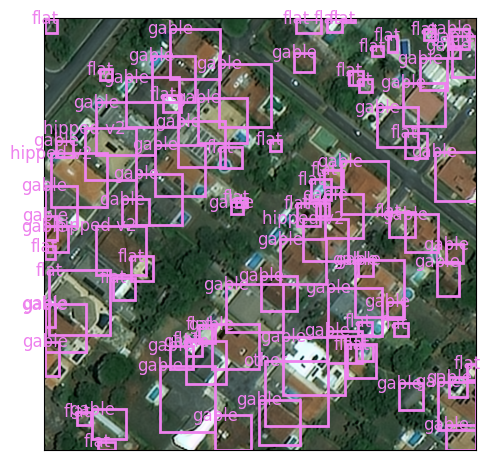

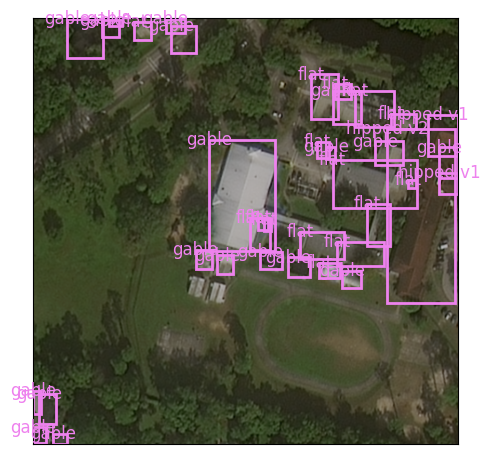

In [ ]:
model_config = {
    "num_classes": 13,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/dfc23/checkpoint.pth.tar"
labels = ["no-data","flat","gable","gambrel","row","multiple eave","hipped v1","hipped v2","mansard","pyramid","arched","revolved","other"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/dfc23/track1_test_data/rgb/P_1473.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/dfc23/track1_test_data/rgb/P_2155.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/dfc23/track1_test_data/rgb/P_2372.tif')
fig = model.detect_objects(image, labels, transform)